In [ ]:
import numpy as np
import pandas as pd
import torch.nn as nn
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

In [ ]:
SEED = 42
BATCH_SIZE = 128
HISTORY_LEN = 10 

In [32]:
# Load the .npz file
data = np.load("../data/poc_dataset/monolithic_dataset.npz")

df = pd.DataFrame({key: data[key] for key in data.files})

df.head()

,timestep,rollout_id,vehicle_id,world_id,x,y,yaw,v,accel,steering,delta_v,delta_yaw,ground_truth_pitch,ground_truth_drag,ground_truth_wheelbase
0,0,0,0,0,0.000000,0.000000,0.000000,0.000000,-2.350422,0.413955,-0.068715,0.000000,-0.099669,0.1,0.33
1,1,0,0,0,0.000000,0.000000,0.000000,-0.068715,-2.274969,0.409751,-0.064598,-0.004522,-0.099669,0.1,0.33
2,2,0,0,0,-0.003436,0.000000,-0.004522,-0.133313,-2.192951,0.405124,-0.060174,-0.008662,-0.099669,0.1,0.33
3,3,0,0,0,-0.010101,0.000030,-0.013184,-0.193487,-2.104667,0.400098,-0.055460,-0.012398,-0.099668,0.1,0.33
4,4,0,0,0,-0.019775,0.000158,-0.025582,-0.248947,-2.010444,0.394700,-0.050473,-0.015712,-0.099664,0.1,0.33


# Data Preprocessing

### Split into Train/Test
* In Distribution = vehicle 1, worlds 1 & 2
* Train: 60% of trajs
* Val: 20% of trajs
* Test: 20% of trajs
    * Also will test on OOD (ie unseen worlds, unseen vehicle, and unseen vehicle in unseen world)

In [ ]:
in_distribution_data = df[(df['vehicle_id'] == 0) & (df['world_id'].isin([0, 1]))]

rollout_world_map = in_distribution_data[["rollout_id", "world_id"]].drop_duplicates()

train_df, temp_df = train_test_split(
    rollout_world_map,
    test_size=0.4,
    stratify=rollout_world_map['world_id'], 
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df, 
    test_size=0.5, 
    stratify=temp_df['world_id'], 
    random_state=SEED
)

train_rollout_ids = train_df['rollout_id']
val_rollout_ids = val_df['rollout_id']
test_rollout_ids = test_df['rollout_id']

train_data = in_distribution_data[in_distribution_data['rollout_id'].isin(train_rollout_ids)]
val_data = in_distribution_data[in_distribution_data['rollout_id'].isin(val_rollout_ids)]
test_data_in_dist = in_distribution_data[in_distribution_data['rollout_id'].isin(test_rollout_ids)]

print("Train Shape: ", train_data.shape)
print("Val Shape: ", val_data.shape)
print("Test Shape: ", test_data_in_dist.shape)

Train Shape:  (36000, 15)
Val Shape:  (12000, 15)
Test Shape:  (12000, 15)


### Additionally create some splits for OOD testing

In [161]:
test_ood_terrain = df[(df['vehicle_id'] == 0) & (df['world_id'] == 2)]
test_ood_vehicle = df[(df['vehicle_id'] == 1) & (df['world_id'].isin([0, 1]))]
test_ood_both = df[(df['vehicle_id'] == 1) & (df['world_id'] == 2)]

raw_splits = {
    'train': train_data,
    'val': val_data,
    'test_in_dist': test_data_in_dist,
    'test_ood_terrain': test_ood_terrain,
    'test_ood_vehicle': test_ood_vehicle,
    'test_ood_both': test_ood_both
}

### Isolate Features and Targets

In [162]:
targets = ['delta_v', 'delta_yaw']
features = ['v', 'accel', 'steering']

# Add rollout_id to X dataframe so I can group by it later
features_with_meta = ['rollout_id'] + features 

datasets = {}
for split_name, data in raw_splits.items():
    datasets[split_name] = {
        'X': data[features_with_meta],
        'y': data[targets]
    }

### Normalize & Convert to Dataloaders

In [163]:
import numpy as np

HISTORY_LEN = 10 

x_scaler = StandardScaler()
y_scaler = StandardScaler()
x_scaler.fit(datasets['train']['X'][features]) 
y_scaler.fit(datasets['train']['y'])

dataloaders = {}

for split_name, data in datasets.items():
    X_scaled_vals = x_scaler.transform(data['X'][features])
    y_scaled_vals = y_scaler.transform(data['y'])
    
    # Create temporary dataframes with the scaled values to easily group by rollout_id
    X_scaled_df = pd.DataFrame(X_scaled_vals, columns=features)
    X_scaled_df['rollout_id'] = data['X']['rollout_id'].values
    y_scaled_df = pd.DataFrame(y_scaled_vals, columns=targets)
    
    X_seqs, y_seqs = [], [] # will become 3D lists (#sequences, sequence_len, #features)
    
    # 4. Slide window over each rollout individually
    for rollout_id, rollout_indices in X_scaled_df.groupby('rollout_id').groups.items():
        this_rollout_X = X_scaled_df.loc[rollout_indices, features].values
        this_rollout_y = y_scaled_df.loc[rollout_indices].values
        
        # Build sequences for this specific rollout
        for i in range(len(this_rollout_X) - HISTORY_LEN):
            X_seqs.append(this_rollout_X[i : i + HISTORY_LEN])
            y_seqs.append(this_rollout_y[i + HISTORY_LEN])
            
    X_tensor = torch.tensor(np.array(X_seqs), dtype=torch.float32)
    y_tensor = torch.tensor(np.array(y_seqs), dtype=torch.float32)
    
    # 6. Build DataLoader
    dataset = TensorDataset(X_tensor, y_tensor)
    dataloaders[split_name] = DataLoader(
        dataset, 
        batch_size=BATCH_SIZE, 
        shuffle=(split_name == 'train')
    )

Inspect a batch / shapes

In [77]:
X, y = next(iter(dataloaders['train']))
print("Feature Shape: ", X.shape)
print("Target Shape: ", y.shape)

Feature Shape:  torch.Size([128, 10, 3])
Target Shape:  torch.Size([128, 2])


In [ ]:
X[:, -1, :]

## Simple Markovian Model

In [96]:
class MarkovDynamicsModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(3, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.Linear(64, 2)
        )
        
    def forward(self, X):
        return self.layers(X)

### Train

In [106]:
NUM_EPOCHS = 100

markov_model = MarkovDynamicsModel()
optimizer = torch.optim.Adam(markov_model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

loss_history = {
    'train': [],
    'val': []
}

for epoch in range(NUM_EPOCHS):
    markov_model.train()
    train_loss = 0
    for X, y in dataloaders['train']:
        X = X[:, -1, :] # Only use last (current) timestep in history
        optimizer.zero_grad()
        pred = markov_model(X)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        
    markov_model.eval()
    val_loss = 0
    with torch.no_grad():
        for X, y in dataloaders['val']:
            X = X[:, -1, :] # Only use last (current) timestep in history
            pred = markov_model(X)
            loss = criterion(pred, y)
            val_loss += loss.item()
            
    loss_history['train'].append(train_loss)
    loss_history['val'].append(val_loss)
    
    if epoch % 10 == 0:
        print("Epoch: ", epoch)
        print(f"Train Loss: {train_loss:.4f}")
        print(f"Val Loss: {val_loss:.4f}")

Epoch:  0
Train Loss: 29.2757
Val Loss: 4.8483
Epoch:  10
Train Loss: 11.9897
Val Loss: 5.0550
Epoch:  20
Train Loss: 11.7130
Val Loss: 5.0621
Epoch:  30
Train Loss: 11.4367
Val Loss: 5.3520
Epoch:  40
Train Loss: 11.2498
Val Loss: 5.4421
Epoch:  50
Train Loss: 11.0952
Val Loss: 5.4913
Epoch:  60
Train Loss: 10.9207
Val Loss: 5.2805
Epoch:  70
Train Loss: 10.9125
Val Loss: 5.5243
Epoch:  80
Train Loss: 10.7359
Val Loss: 5.5107
Epoch:  90
Train Loss: 10.5719
Val Loss: 5.8648


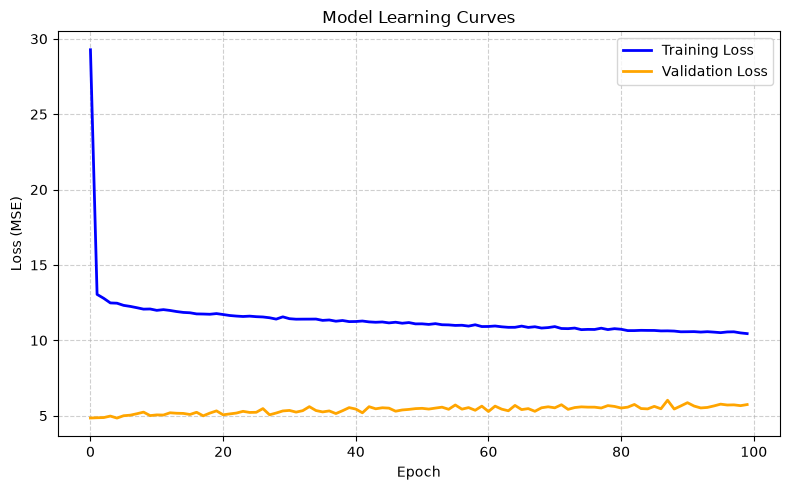

In [146]:
def plot_curves(loss_history):
    plt.figure(figsize=(8, 5))

    # Extract and plot both curves
    plt.plot(loss_history['train'], label='Training Loss', linewidth=2, color='blue')
    plt.plot(loss_history['val'], label='Validation Loss', linewidth=2, color='orange')

    # Format the graph for readability
    plt.title('Model Learning Curves')
    plt.xlabel('Epoch')
    plt.ylabel('Loss (MSE)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

    # Render the plot
    plt.tight_layout()
    return plt

plot_curves(loss_history).show()

## Baseline Model With State History

In [111]:
X, y = next(iter(dataloaders['train']))
print(X.shape)
print(y.shape)

torch.Size([128, 10, 3])
torch.Size([128, 2])


In [139]:
class SequenceDynamicsModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=3, hidden_size=64, batch_first=True)
        self.regression_head = nn.Linear(64, 2)
        
    def forward(self, X):
        output, hidden = self.lstm(X)
        final_output = output[:, -1, :]
        return self.regression_head(final_output)

In [151]:
NUM_EPOCHS = 100

sequence_model = SequenceDynamicsModel()
optimizer = torch.optim.Adam(sequence_model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

loss_history = {
    'train' : [],
    'val' : []
}

for epoch in range(NUM_EPOCHS):
    train_loss = 0
    sequence_model.train()
    for X, y in dataloaders['train']:
        optimizer.zero_grad()
        pred = sequence_model(X)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    val_loss = 0
    sequence_model.eval()
    with torch.no_grad():
        for X, y in dataloaders['val']:
            pred = sequence_model(X)
            loss = criterion(pred, y)
            val_loss += loss.item()
    
    loss_history['train'].append(train_loss)
    loss_history['val'].append(val_loss)
        
    if epoch % 20 == 0:
        print(f"Epoch {epoch} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 0 | Train Loss: 61.8941 | Val Loss: 5.7107
Epoch 20 | Train Loss: 1.8250 | Val Loss: 0.9282
Epoch 40 | Train Loss: 1.3614 | Val Loss: 0.5741
Epoch 60 | Train Loss: 1.1528 | Val Loss: 0.4371
Epoch 80 | Train Loss: 0.9532 | Val Loss: 0.3554


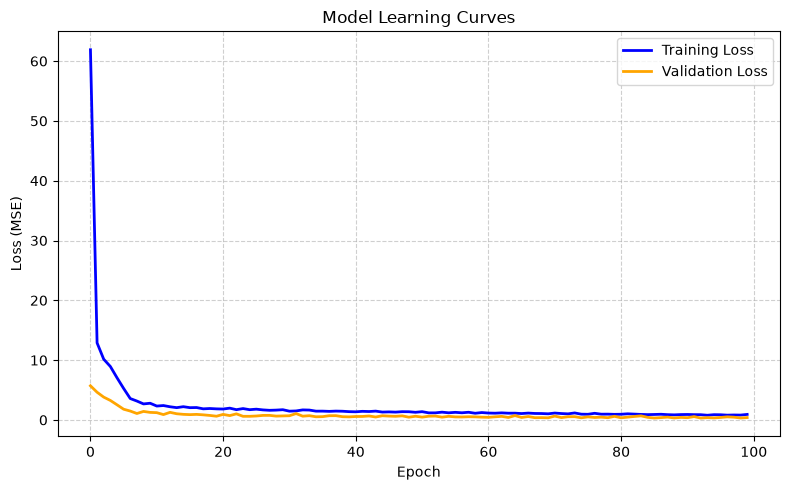

In [152]:
plot_curves(loss_history).show()

In [167]:
def evaluate_generalization(model, dataloader, scaler):
    model.eval()
    all_preds, all_targets = [], []
    
    with torch.no_grad():
        for X, y in dataloader:
            preds = model(X)
            all_preds.append(np.array(preds.cpu().tolist()))
            all_targets.append(np.array(y.cpu().tolist()))
            
    # Concatenate all batches in the test set
    all_preds = np.vstack(all_preds)
    all_targets = np.vstack(all_targets)
    
    # Inverse transform to restore original physical units
    preds_physical = scaler.inverse_transform(all_preds)
    targets_physical = scaler.inverse_transform(all_targets)
    
    # Calculate RMSE for each target independently (axis=0)
    rmse = np.sqrt(np.mean((preds_physical - targets_physical)**2, axis=0))
    return rmse # Returns [rmse_delta_v, rmse_delta_yaw]

,Test Domain,Delta V RMSE,Delta Yaw RMSE
0,test_in_dist,0.0069,0.0028
1,test_ood_terrain,0.0486,0.0109
2,test_ood_vehicle,0.0065,0.0313
3,test_ood_both,0.0287,0.0334


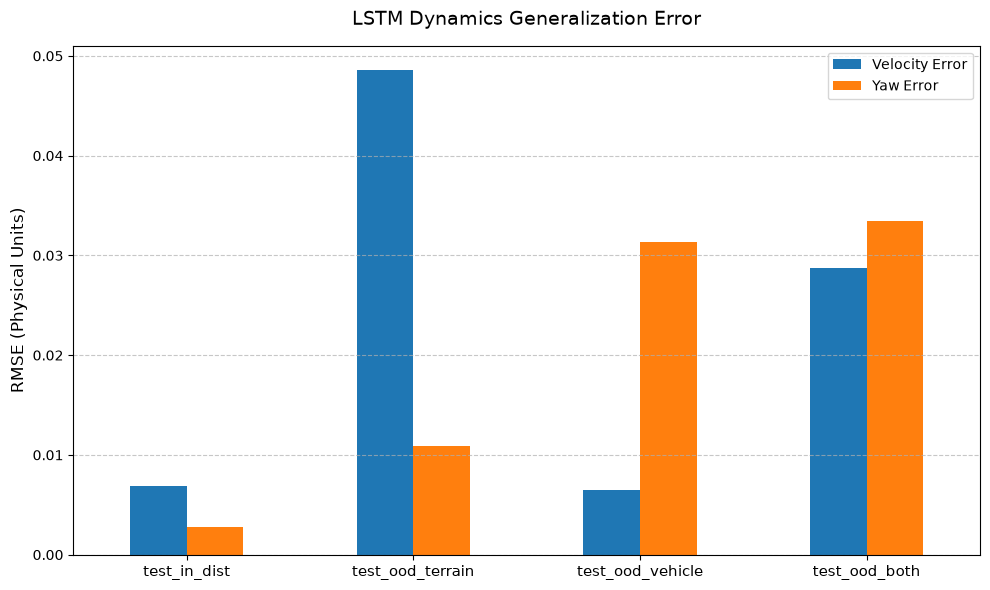

In [168]:
eval_splits = ['test_in_dist', 'test_ood_terrain', 'test_ood_vehicle', 'test_ood_both']
results = []

# Run evaluations
for split in eval_splits:
    # Pass in the specific dataloader and your fitted y_scaler
    rmse_v, rmse_yaw = evaluate_generalization(sequence_model, dataloaders[split], y_scaler)
    
    results.append({
        'Test Domain': split,
        'Delta V RMSE': np.round(rmse_v, 4),
        'Delta Yaw RMSE': np.round(rmse_yaw, 4)
    })

# Render Table
results_df = pd.DataFrame(results)
display(results_df) # Use print() if not in a Jupyter notebook

# Render Bar Chart for Slides
results_df.set_index('Test Domain').plot(
    kind='bar', 
    figsize=(10, 6), 
    color=['#1f77b4', '#ff7f0e']
)

plt.title('LSTM Dynamics Generalization Error', fontsize=14, pad=15)
plt.ylabel('RMSE (Physical Units)', fontsize=12)
plt.xlabel('')
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(['Velocity Error', 'Yaw Error'])
plt.tight_layout()
plt.show()

In [165]:
import numpy as np